# Imports

In [15]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc 
import anndata as ad
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns


# Metrics
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from scipy.stats import entropy

For all the methods, we will use the same amount of data.

- We will choose cells which have at least 200 genes `sc.pp.filter_cells(adata, min_genes = 200)`

- We will choose genes which are at least in 10 cells `sc.pp.filter_genes(adata, min_cells=10)`

- As seen in the EDA,  we will choose 2000 top HVG, which represent Highly Variable Genes, as they contain actual valuable information.
This is a strict cutoff we are introducing manually, therefore we should take it into account. Maybe 2134 HVG is better, however, this seems like a reasonable value and it also represents a big dataset reduction which will improve our computational power.

# Loading Data

In [ ]:
# processing
from data.load_data import load_wu2021, first_col, SEED, N_CELLS

def find_project_root(start=None):
    try:
        start = Path(start or __file__).resolve()   
    except NameError:
        start = Path.cwd().resolve()                
    for parent in [start] + list(start.parents):
        if (parent / "data").exists() or (parent / "README.md").exists():
            return parent
    raise FileNotFoundError("Could not find project root containing 'data/' or README.md.")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
H5AD_PATH = DATA_DIR / "wu_2021_breast_cancer.h5ad"
GEO_DIR = DATA_DIR / "geo_data"

adata = load_wu2021()

In [10]:
# Same processing as before
def is_integer_counts(X, n=500):
    sub = X[:n].toarray() if hasattr(X[:n], "toarray") else np.asarray(X[:n])
    return bool(np.all(sub >= 0) and np.allclose(sub, np.round(sub)))

if not is_integer_counts(adata.X):
    if adata.raw is not None:
        adata = adata.raw.to_adata()

# Map Ensembl IDs to Gene Names if present
if "feature_name" in adata.var:
    adata.var["ensembl_id"] = adata.var_names
    adata.var_names = adata.var["feature_name"].astype(str)

adata.var_names_make_unique()

# Standardize Column Metadata
def first_col(obs, candidates):
    for c in candidates:
        if c in obs.columns:
            return c
    raise KeyError(f"None of {candidates} found in obs: {list(obs.columns)}")

COLMAP = {
    "patient":        first_col(adata.obs, ["orig.ident", "donor_id", "Patient", "patient"]),
    "subtype":        first_col(adata.obs, ["subtype", "Subtype", "clinical_subtype", "disease"]),
    "celltype":       first_col(adata.obs, ["celltype_major", "author_cell_type", "cell_type"]),
    "celltype_minor": first_col(adata.obs, ["celltype_minor", "celltype_major", "author_cell_type", "cell_type"]),
}

for std, orig in COLMAP.items():
    adata.obs[std] = adata.obs[orig].astype(str).astype("category")

# Keep subtype as a plain string inside obs to prevent categorical list aggregation errors
adata.obs["subtype"] = adata.obs["subtype"].astype(str)

# Data Filtering and Normalization

In [11]:
N_HVG = 2000
N_LATENT = 10
SEED = 42
MIN_GENES = 200
MIN_CELLS = 10

In [ ]:
adata.layers["counts"] = adata.X.copy() # Raw counts are saved just in case

sc.pp.filter_cells(adata, min_genes=MIN_GENES)
sc.pp.filter_genes(adata, min_cells=MIN_CELLS)


# Normalization and log-transform
sc.pp.normalize_total(adata, target_sum=1e4) # Normalizes total counts per cell to 10000
sc.pp.log1p(adata)

# Chosing HVGs
try:
    sc.pp.highly_variable_genes(
        adata, n_top_genes=N_HVG, flavor="seurat_v3",
        layer="counts", batch_key="patient", subset=True
    )
except Exception as e:
    print("Per-patient HVG selection failed, switching to global HVGs:", e)
    sc.pp.highly_variable_genes(
        adata, n_top_genes=N_HVG, flavor="seurat_v3",
        layer="counts", subset=True
    )

Per-patient HVG selection failed, switching to global HVGs: b'reciprocal condition number  7.4327e-15'


# Baseline Model

We will apply PCA on log-normalized data as a baseline model to compare with the remaining models.


In [13]:
adata_pca = adata.copy()
sc.pp.scale(adata_pca, max_value=10)
sc.tl.pca(adata_pca, n_comps=N_LATENT, random_state=SEED)

# Copying PCA latent embedding back to main AnnData
adata.obsm["X_pca"] = adata_pca.obsm["X_pca"].copy()

c:\Users\19aca\AppData\Local\Python\pythoncore-3.14-64\Lib\functools.py:982: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


c:\Users\19aca\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


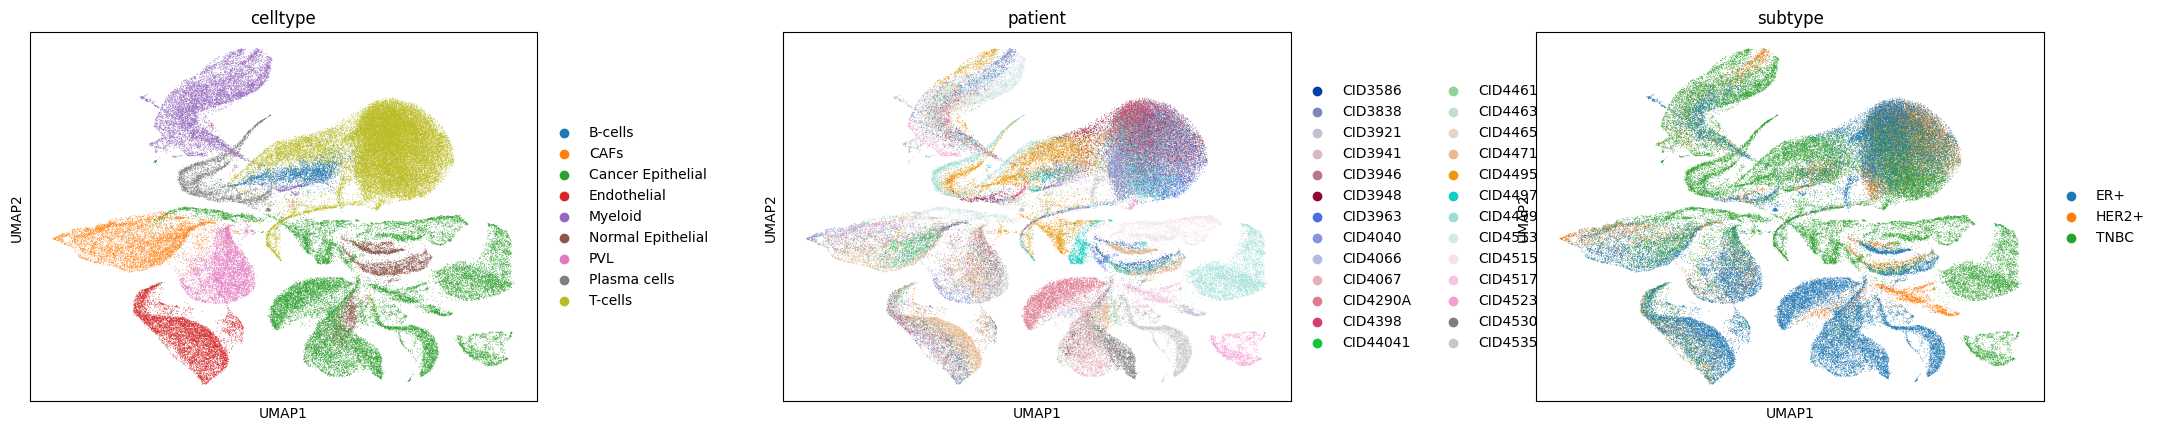

In [14]:
# KNN graph and UMAP
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca")
sc.tl.umap(adata)
adata.obsm["X_umap_pca"] = adata.obsm["X_umap"].copy()

sc.pl.umap(adata, color=["celltype", "patient", "subtype"], wspace=0.35)

## PCA Evaluation Metrics

We will compute different evaluation metrics whihc will be used later for comparing models

*To do: explain what each of the metrics compute*

In [16]:
y_true = adata.obs["celltype"].astype(str).values
n_celltypes = adata.obs["celltype"].nunique()

# Unsupervised Biological (K-Means ARI and NMI)
kmeans = KMeans(n_clusters=n_celltypes, random_state=SEED, n_init=10)
pca_cluster_labels = kmeans.fit_predict(adata.obsm["X_pca"])

pca_ari = adjusted_rand_score(y_true, pca_cluster_labels)
pca_nmi = normalized_mutual_info_score(y_true, pca_cluster_labels)

# Silhoute score (ASW) we take a subset of our data
sub_idx = np.random.choice(adata.shape[0], size=min(10000, adata.shape[0]), replace=False)
X_pca_sub = adata.obsm["X_pca"][sub_idx]

asw_celltype = silhouette_score(X_pca_sub, adata.obs["celltype"].iloc[sub_idx])
asw_patient = silhouette_score(X_pca_sub, adata.obs["patient"].iloc[sub_idx])

# Batch entropy
def compute_batch_entropy(X, patient_labels, k=50):
    nn = NearestNeighbors(n_neighbors=k, n_jobs=-1).fit(X)
    indices = nn.kneighbors(X, return_distance=False)
    entropies = [entropy(pd.Series(patient_labels[nbrs]).value_counts(normalize=True)) for nbrs in indices]
    return np.mean(entropies)

pca_batch_entropy = compute_batch_entropy(adata.obsm["X_pca"], adata.obs["patient"].values, k=50)

# PCA metrics, in the future, we will save this to CSV, arrows indicate if high values is btter or not
pca_metrics = pd.DataFrame([{
    "Model": "PCA Baseline",
    "ARI (Cell Type ↑)": pca_ari,
    "NMI (Cell Type ↑)": pca_nmi,
    "ASW (Cell Type ↑)": asw_celltype,
    "ASW (Patient ↓)": asw_patient,
    "Batch Entropy (↑)": pca_batch_entropy
}]).set_index("Model")

print(pca_metrics)

              ARI (Cell Type ↑)  NMI (Cell Type ↑)  ASW (Cell Type ↑)  \
Model                                                                   
PCA Baseline           0.645611           0.711716           0.286625   

              ASW (Patient ↓)  Batch Entropy (↑)  
Model                                             
PCA Baseline        -0.201067           1.138922  


**To do: Missing conclusions, brief model explanation and analysis for PCA**